# 06 Directed network and hypergraph (Section 6.6, Figures 7 and 8)

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NETWORK_DIR = Path("ablation_outputs/A0_full/network")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
TEST_START, TEST_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31")

flow = pd.read_parquet(NETWORK_DIR / "flow_edges.parquet")
flow["date"] = pd.to_datetime(flow["date"])
hyper = pd.read_parquet(NETWORK_DIR / "hyperedges.parquet")
hyper["date"] = pd.to_datetime(hyper["date"])

## Figure 7: network strength over time

Mean absolute edge weight by year:
date
2018    0.173
2019    0.172
2020    0.224
2021    0.175
2022    0.174


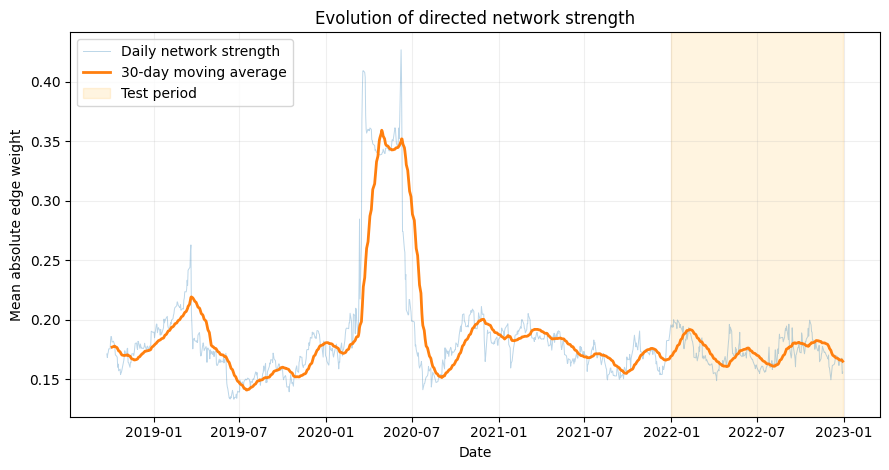

In [2]:
daily_strength = flow.assign(abs_weight=flow["weight"].abs()).groupby("date")["abs_weight"].mean().sort_index()
rolling_strength = daily_strength.rolling(window=30, min_periods=10).mean()

print("Mean absolute edge weight by year:")
print(daily_strength.groupby(daily_strength.index.year).mean().round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(daily_strength.index, daily_strength.values, linewidth=0.7, alpha=0.3, label="Daily network strength")
ax.plot(rolling_strength.index, rolling_strength.values, linewidth=2, label="30-day moving average")
ax.axvspan(TEST_START, TEST_END, alpha=0.12, color="orange", label="Test period")
ax.set_xlabel("Date")
ax.set_ylabel("Mean absolute edge weight")
ax.set_title("Evolution of directed network strength")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIG_DIR / "network_strength_evolution.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 8: average signed edge weights in 2022

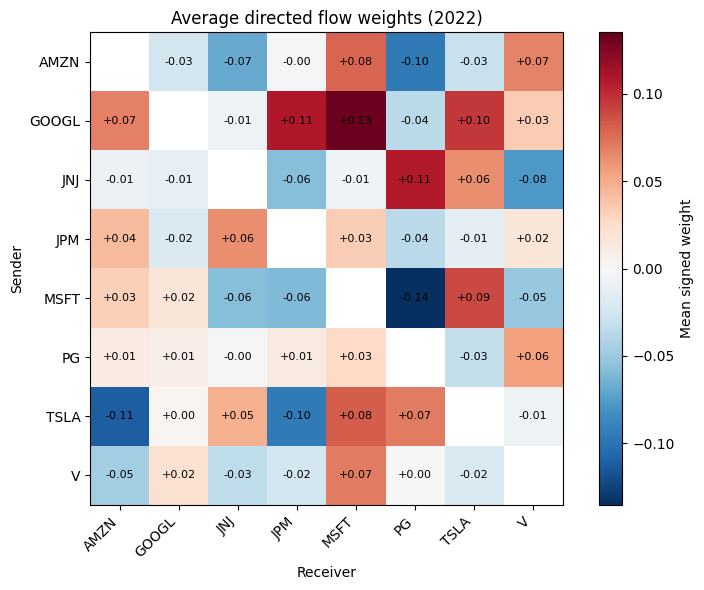

sender  receiver
MSFT    PG         -0.135
TSLA    AMZN       -0.111
GOOGL   JPM         0.108
        MSFT        0.133
dtype: float64


In [3]:
test = flow[flow["date"].between(TEST_START, TEST_END)]
tickers = sorted(set(test["sender"]) | set(test["receiver"]))
# self-edges do not exist, so the diagonal stays empty
matrix = test.pivot_table(index="sender", columns="receiver", values="weight", aggfunc="mean")
matrix = matrix.reindex(index=tickers, columns=tickers)

fig, ax = plt.subplots(figsize=(8, 6))
vmax = np.nanmax(np.abs(matrix.to_numpy()))
im = ax.imshow(matrix.to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(tickers)), tickers, rotation=45, ha="right")
ax.set_yticks(range(len(tickers)), tickers)
ax.set_xlabel("Receiver")
ax.set_ylabel("Sender")
ax.set_title("Average directed flow weights (2022)")
for i in range(len(tickers)):
    for j in range(len(tickers)):
        value = matrix.iloc[i, j]
        if np.isfinite(value):
            ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="Mean signed weight")
plt.tight_layout()
plt.savefig(FIG_DIR / "network_2022_signed_flow_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print(matrix.stack().dropna().sort_values().iloc[[0, 1, -2, -1]].round(3))

## Community co-membership in 2022

In [4]:
h22 = hyper[hyper["date"].between(TEST_START, TEST_END)]
n_days = h22["date"].nunique()
together = {pair: 0 for pair in combinations(tickers, 2)}
for members in h22["members"].astype(str):
    for pair in combinations(sorted(members.split("|")), 2):
        if pair in together:
            together[pair] += 1
co = pd.Series(together, name="share_of_days").div(n_days).sort_values(ascending=False)
print(f"{n_days} days in 2022")
print(co.head(5).round(3).to_string())

251 days in 2022
GOOGL  MSFT     0.554
JNJ    TSLA     0.482
AMZN   GOOGL    0.474
       MSFT     0.466
MSFT   TSLA     0.438


In [ ]:
# Jaccard similarity of each community's members on consecutive day, averaged over communities and days, against random assignments of the stocks to communities of the same sizes
def mean_jaccard(days):
    vals = []
    for prev, cur in zip(days[:-1], days[1:]):
        for cid in prev.keys() & cur.keys():
            vals.append(len(prev[cid] & cur[cid]) / len(prev[cid] | cur[cid]))
    return float(np.mean(vals))


def shuffle_members(day, rng):
    stocks = rng.permutation([t for members in day.values() for t in members])
    out, i = {}, 0
    for cid, members in day.items():
        out[cid] = set(stocks[i:i + len(members)])
        i += len(members)
    return out


days = [{int(r.community_id): set(str(r.members).split("|")) for r in g.itertuples()}
        for _, g in h22.sort_values("date").groupby("date")]
rng = np.random.default_rng(42)
observed = mean_jaccard(days)
randomised = np.mean([mean_jaccard([shuffle_members(d, rng) for d in days]) for _ in range(1000)])
print(f"Day-to-day Jaccard similarity: {observed:.3f} (random assignments: {randomised:.3f})")

Day-to-day Jaccard similarity: 0.311 (random assignments: 0.216)
